# SINASC 2014–2024 — comparabilidade, suporte e positividade temporal (08)

> **tl;dr.** O controle positivo de 2024 reproduziu integralmente o artefato certificado. Nos 11 anos, nenhum escore ficou fora de ([0,01; 0,99]); a fração fora de ([0,05; 0,95]) variou entre **3,86% e 6,55%**. O ESS relativo permaneceu entre **67,6% e 75,2%** no controle e **97,6% e 99,2%** no tratado. Não há perfis marginais com tratamento quase determinístico; as únicas células com menos de 100 registros são de idade materna ignorada e contêm ambos os grupos. O desequilíbrio bruto intra-ano é material em toda a série (pior (|SMD|=0,375) a (0,442)), enquanto a composição converge gradualmente para 2024.

**Conclusão operacional:** o diagnóstico permite **planejar** o notebook 09 com estimação separada por ano e sensibilidade obrigatória 2018–2024. Isso não estabelece intercambialidade, não prova causalidade e não autoriza pooling. Esta rodada não estima efeitos causais.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Image, display

raiz = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / 'src').exists()).resolve()
sys.path.insert(0, str(raiz))
assert Path(sys.executable).resolve() == (raiz / '.venv/Scripts/python.exe').resolve(), 'Use a .venv do projeto'

from src import temporal as tp
from src.visualizacao import configurar_plotly, aplicar_tema_ipt

configurar_plotly()
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

pasta_tabelas = raiz / 'outputs/temporal/tabelas'
pasta_cache = raiz / 'data/interim/temporal_overlap'
pasta_figuras = raiz / 'outputs/figures'
pasta_figuras.mkdir(parents=True, exist_ok=True)

def mostrar(fig, titulo, nome, altura=560):
    aplicar_tema_ipt(fig, titulo)
    fig.update_layout(width=1100, height=altura, margin=dict(l=90, r=50, t=100, b=80))
    fig.update_xaxes(dtick=1, automargin=True)
    fig.update_yaxes(automargin=True)
    caminho = pasta_figuras / f'temporal08_{nome}.png'
    fig.write_image(caminho)
    display(Image(filename=str(caminho)))

JANELA_PRINCIPAL = list(tp.JANELAS['principal']['anos'])
JANELA_SENSIBILIDADE = list(tp.JANELAS['sensibilidade']['anos'])
print('Janela principal:', JANELA_PRINCIPAL)
print('Sensibilidade obrigatória:', JANELA_SENSIBILIDADE)

Janela principal: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Sensibilidade obrigatória: [2018, 2019, 2020, 2021, 2022, 2023, 2024]


## 1. Objetivo

Pergunta central: **as populações anuais possuem composição, suporte e positividade suficientemente comparáveis para justificar, em etapa posterior, estimativas causais separadas por ano?**

A unidade é um nascido vivo elegível na população principal congelada. O tratamento continua sendo início do pré-natal nos meses 1–3 versus 4–9; o desfecho continua sendo baixo peso ao nascer, mas **não é modelado nesta fase**. As sete covariáveis são todas pré-tratamento segundo o contrato certificado. Propensity aqui é diagnóstico da atribuição de T, não estimativa de efeito.

## 2. Contratos temporais

A janela principal 2014–2024 usa v1.1 (v1 + H1). A sensibilidade 2018–2024 usa v1 estrito. H1 harmoniza somente o identificador; não altera tratamento, desfecho, covariáveis, frequências ou regras de inclusão. Para 2024, a ordem física certificada é preservada; 2014–2023 usam ordem determinística pela chave temporal.

In [2]:
contrato_temporal = json.loads((raiz / 'outputs/temporal/contrato_temporal.json').read_text(encoding='utf-8'))
contrato_diagnostico = json.loads((raiz / 'outputs/temporal/contrato_diagnostico_temporal.json').read_text(encoding='utf-8'))
display(pd.DataFrame({
    'janela': ['principal', 'sensibilidade'],
    'anos': ['2014–2024', '2018–2024'],
    'contrato': [tp.JANELAS['principal']['contrato'], tp.JANELAS['sensibilidade']['contrato']],
    'uso': ['resultado principal', 'sensibilidade obrigatória'],
}))
assert contrato_diagnostico['estima_efeito_causal'] is False
assert contrato_diagnostico['ordem_2024'] == tp.ORDEM_2024_CERTIFICADA
assert contrato_diagnostico['ordem_2014_2023'] == tp.ORDEM_CHAVE_TEMPORAL

,janela,anos,contrato,uso
0,principal,2014–2024,v1.1,resultado principal
1,sensibilidade,2018–2024,v1,sensibilidade obrigatória


## 3. Janelas principal e de sensibilidade

A sensibilidade é somente um recorte pré-especificado dos mesmos resultados anuais. Nenhum modelo é reajustado para formar a janela 2018–2024 e nenhuma janela é escolhida com base nos resultados.

## 4. Limites pré-especificados

Fixados antes dos novos propensities:

- (|SMD| > 0,10);
- célula pequena quando T=0 < 100 ou T=1 < 100;
- tratamento extremo quando (P(T=1)leq0,01) ou (P(T=1)geq0,99);
- frações fora de ([0,01;0,99]) e ([0,05;0,95]).

São diagnósticos, não regras automáticas de exclusão.

In [3]:
limites = contrato_diagnostico['limites_pre_especificados']
display(pd.Series(limites, name='valor').to_frame())
assert limites['smd_abs'] == 0.10
assert limites['celula_minima_por_grupo'] == 100
assert limites['tratamento_extremo_inferior'] == 0.01
assert limites['tratamento_extremo_superior'] == 0.99

,valor
smd_abs,0.1
celula_minima_por_grupo,100
tratamento_extremo_inferior,0.01
tratamento_extremo_superior,0.99
faixas_propensity,"[[0.01, 0.99], [0.05, 0.95]]"


## 5. Controle positivo 2024 e validação dos caches

Cada cache contém hash do Parquet, código relevante, sequência da chave, features, T, modelo, hiperparâmetros, folds, semente, regra de ordenação e N por grupo. O conteúdo não usa timestamp científico. O notebook valida os 11 caches antes de ler as tabelas agregadas.

In [4]:
controle = json.loads((raiz / 'outputs/temporal/controle_positivo_2024.json').read_text(encoding='utf-8'))
benchmark = pd.read_csv(pasta_tabelas / 'benchmark_propensity_anual.csv')
codigo_atual = tp.sha256_codigo_relevante_temporal(raiz)
caches_validados = []

for linha in benchmark.itertuples(index=False):
    meta_path = pasta_cache / f'propensity_{linha.ano}_{linha.fingerprint_cache[:16]}.json'
    metadados = json.loads(meta_path.read_text(encoding='utf-8'))
    assert metadados['codigo_relevante_sha256'] == codigo_atual
    predicoes = tp.carregar_cache_propensity(pasta_cache, metadados)
    assert predicoes is not None and len(predicoes) == linha.n
    caches_validados.append({'ano': linha.ano, 'n': len(predicoes),
                              'cache_mb': meta_path.with_suffix('.npz').stat().st_size / 1e6,
                              'fingerprint': linha.fingerprint_cache[:16]})
    del predicoes
    gc.collect()

assert controle['aprovado'] and not controle['divergencias']
display(pd.DataFrame(caches_validados).sort_values('ano'))
print(controle['status'])
display(pd.Series(controle['resumo_observado'], name='2024').to_frame().head(18))

,ano,n,cache_mb,fingerprint
1,2014,2691119,13.059513,1767aecd0046669f
2,2015,2745846,13.300532,ee9538711fa6d691
3,2016,2626594,12.707246,069df029c583533f
4,2017,2695676,12.856032,bfca193dd026391f
5,2018,2734473,12.931914,9e3dab5824f6c32e
6,2019,2645383,12.463185,b82422c5a941ddf4
7,2020,2535311,11.977744,0f29a6708834afc4
8,2021,2481267,11.691084,552b7bbe3ac8726d
9,2022,2397626,11.248522,94be134e027dc8e1
10,2023,2389346,11.154177,ade19563f5bc41be


CONTROLE_POSITIVO_2024_APROVADO


,2024
ano,2.024000e+03
n,2.251570e+06
n_t0,3.095250e+05
n_t1,1.942045e+06
auc_oof,6.628731e-01
propensity_min,2.310277e-01
propensity_max,9.770504e-01
suporte_comum_inferior,3.068074e-01
suporte_comum_superior,9.739275e-01
ess_t0,2.327794e+05


O controle positivo compara N, T, AUC, mínimos, máximos, todos os quantis registrados, interseção de suporte, contagens sob os dois intervalos e o histograma oficial de 100 bins. Resultado: **CONTROLE_POSITIVO_2024_APROVADO**. A ordem certificada foi reproduzível; não se aplica a marca de ordem não reproduzível.

In [5]:
nomes = [
    'smd_intra_ano', 'smd_intra_ano_resumo',
    'composicao_vs_2024', 'composicao_vs_2024_resumo',
    'tratamento_anual', 'positividade_perfis', 'positividade_resumo',
    'propensity_anual', 'perfis_fora_suporte', 'benchmark_propensity_anual',
    'comparacao_janelas', 'transicao_2021_2022_anual', 'transicao_2021_2022_periodos',
]
tabelas = {nome: pd.read_csv(pasta_tabelas / f'{nome}.csv') for nome in nomes}
assert tabelas['propensity_anual'].ano.sort_values().tolist() == JANELA_PRINCIPAL
print('Tabelas agregadas carregadas:', ', '.join(nomes))

Tabelas agregadas carregadas: smd_intra_ano, smd_intra_ano_resumo, composicao_vs_2024, composicao_vs_2024_resumo, tratamento_anual, positividade_perfis, positividade_resumo, propensity_anual, perfis_fora_suporte, benchmark_propensity_anual, comparacao_janelas, transicao_2021_2022_anual, transicao_2021_2022_periodos


## 6. SMD intra-ano: T=1 versus T=0

O pior nível de cada variável é calculado com a mesma convenção certificada de 2024. Este é balanço bruto por tratamento dentro do ano, não composição temporal.

,ano,variavel,nivel,smd,abs_smd
68,2014,SITUACAO_CONJUGAL,2,0.441289,0.441289
121,2015,SITUACAO_CONJUGAL,2,0.436424,0.436424
174,2016,SITUACAO_CONJUGAL,2,0.434835,0.434835
227,2017,SITUACAO_CONJUGAL,2,0.439616,0.439616
280,2018,SITUACAO_CONJUGAL,2,0.441538,0.441538
333,2019,SITUACAO_CONJUGAL,2,0.428768,0.428768
386,2020,SITUACAO_CONJUGAL,2,0.415059,0.415059
439,2021,SITUACAO_CONJUGAL,2,0.388937,0.388937
492,2022,SITUACAO_CONJUGAL,2,0.384107,0.384107
545,2023,SITUACAO_CONJUGAL,2,0.384630,0.384630


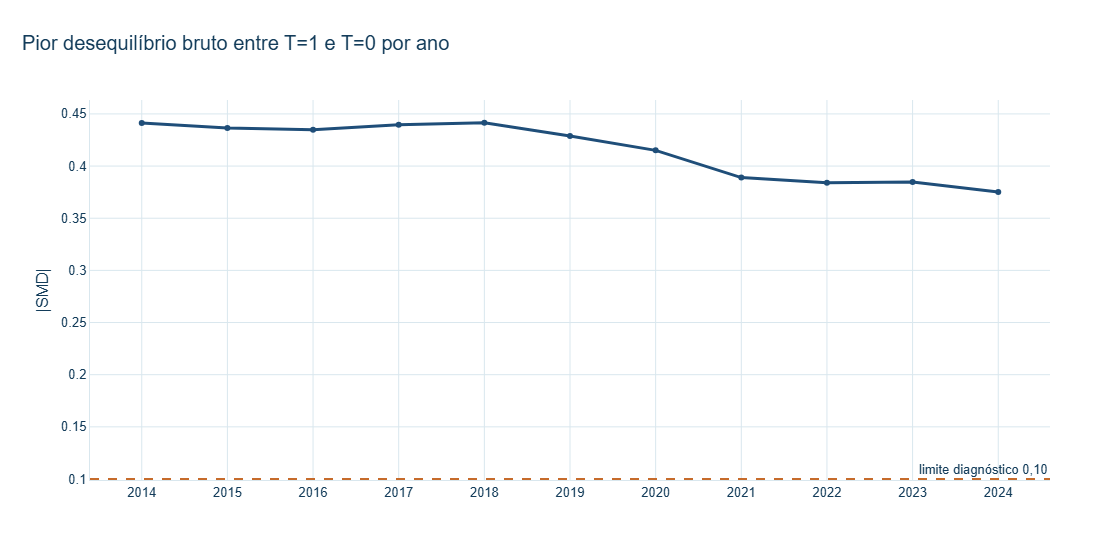

In [6]:
smd = tabelas['smd_intra_ano']
pior_smd = smd.groupby('ano').abs_smd.max().sort_index()
pior_linha = smd.loc[smd.groupby('ano').abs_smd.idxmax(),
                     ['ano', 'variavel', 'nivel', 'smd', 'abs_smd']].sort_values('ano')
display(pior_linha)

fig = go.Figure()
fig.add_scatter(x=pior_smd.index, y=pior_smd.values, mode='lines+markers',
                name='Pior |SMD| no ano', line=dict(color='#1F4E79', width=3))
fig.add_hline(y=0.10, line_dash='dash', line_color='#C66B2B',
              annotation_text='limite diagnóstico 0,10')
fig.update_yaxes(title='|SMD|')
mostrar(fig, 'Pior desequilíbrio bruto entre T=1 e T=0 por ano', 'smd_intra')

O desequilíbrio bruto é material em todos os anos: o pior (|SMD|) varia de 0,375 a 0,442, sempre associado ao nível 2 de situação conjugal. Escolaridade e raça/cor também aparecem entre os maiores contrastes. Há redução depois de 2018, mas nenhum ano se aproxima de balanço bruto global. Isso reforça a necessidade de ajuste; não invalida sozinho um ano e não demonstra controle de confundimento.

## 7. Composição versus 2024

Este SMD compara populações anuais completas e permanece semanticamente separado do SMD T=1/T=0.

,ano,variavel,nivel,smd_temporal,abs_smd_temporal
78,2014,PERDAS_FETAIS_CAT,IGNORADO,0.297774,0.297774
131,2015,PERDAS_FETAIS_CAT,IGNORADO,0.282677,0.282677
184,2016,PERDAS_FETAIS_CAT,IGNORADO,0.255416,0.255416
237,2017,PERDAS_FETAIS_CAT,IGNORADO,0.207089,0.207089
283,2018,SITUACAO_CONJUGAL,5,0.173409,0.173409
336,2019,SITUACAO_CONJUGAL,5,0.148066,0.148066
389,2020,SITUACAO_CONJUGAL,5,0.124845,0.124845
442,2021,SITUACAO_CONJUGAL,5,0.112270,0.112270
495,2022,SITUACAO_CONJUGAL,5,0.077517,0.077517
548,2023,SITUACAO_CONJUGAL,5,0.037938,0.037938


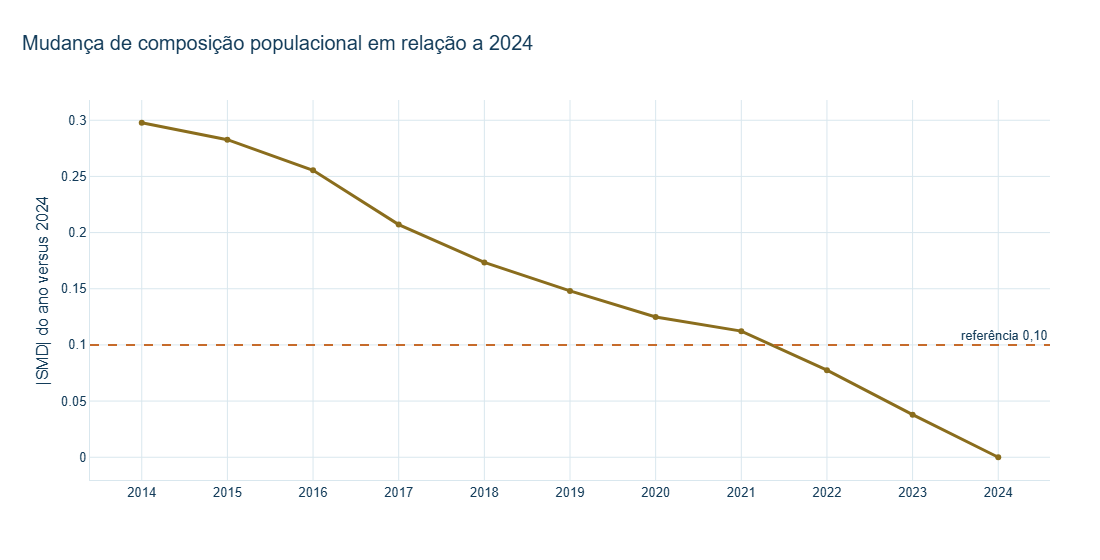

In [7]:
composicao = tabelas['composicao_vs_2024']
pior_comp = composicao.groupby('ano').abs_smd_temporal.max().sort_index()
pior_comp_linha = composicao.loc[composicao.groupby('ano').abs_smd_temporal.idxmax(),
                                 ['ano', 'variavel', 'nivel', 'smd_temporal', 'abs_smd_temporal']].sort_values('ano')
display(pior_comp_linha)

fig = go.Figure()
fig.add_scatter(x=pior_comp.index, y=pior_comp.values, mode='lines+markers',
                name='Pior |SMD temporal|', line=dict(color='#8A6D1D', width=3))
fig.add_hline(y=0.10, line_dash='dash', line_color='#C66B2B',
              annotation_text='referência 0,10')
fig.update_yaxes(title='|SMD| do ano versus 2024')
mostrar(fig, 'Mudança de composição populacional em relação a 2024', 'composicao')

A distância de composição cai de 0,298 em 2014 para 0,038 em 2023 e zero por definição em 2024. Até 2021, ao menos um nível supera 0,10; em 2022–2024, nenhum supera. As maiores diferenças antigas se concentram em perdas fetais ignoradas, situação conjugal e escolaridade. A trajetória é gradual e não mostra ruptura extrema em 2021–2022.

## 8. Distribuição do tratamento

,n,n_t0,n_t1,proporcao_t1,flag_celula_pequena,flag_tratamento_extremo
ano,,,,,,
2014,2691119,577127,2113992,0.785544,False,False
2015,2745846,565595,2180251,0.794018,False,False
2016,2626594,518310,2108284,0.802668,False,False
2017,2695676,511767,2183909,0.810153,False,False
2018,2734473,499451,2235022,0.817350,False,False
2019,2645383,465593,2179790,0.823998,False,False
2020,2535311,444287,2091024,0.824760,False,False
2021,2481267,399172,2082095,0.839126,False,False
2022,2397626,379207,2018419,0.841841,False,False


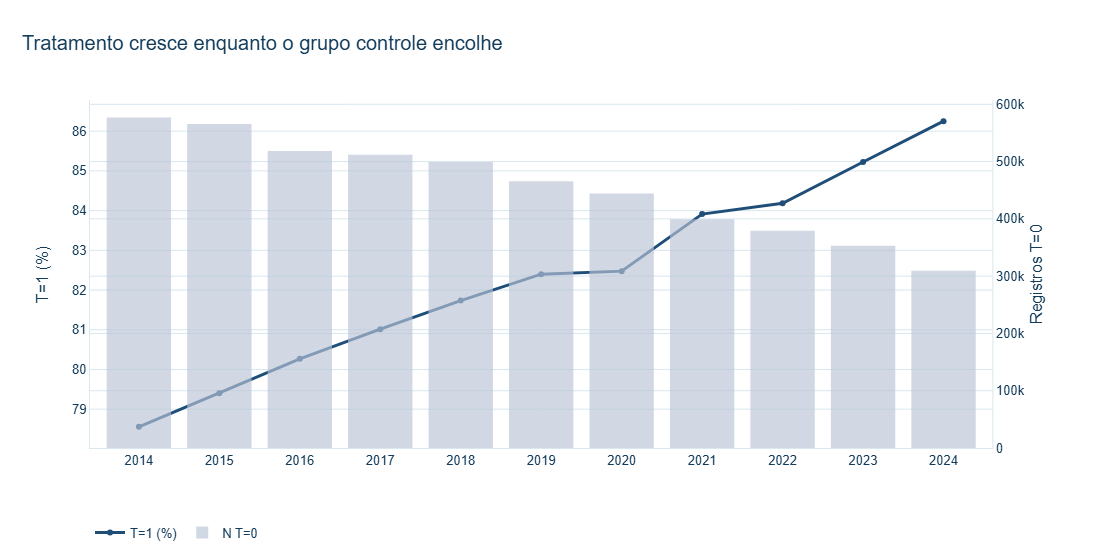

In [8]:
tratamento = tabelas['tratamento_anual']
trat_ano = tratamento[tratamento.granularidade.eq('ano')].sort_values('ano').set_index('ano')
display(trat_ano[['n', 'n_t0', 'n_t1', 'proporcao_t1',
                  'flag_celula_pequena', 'flag_tratamento_extremo']])

fig = make_subplots(specs=[[{'secondary_y': True}]])
fig.add_scatter(x=trat_ano.index, y=100 * trat_ano.proporcao_t1, mode='lines+markers',
                name='T=1 (%)', line=dict(color='#1F4E79', width=3), secondary_y=False)
fig.add_bar(x=trat_ano.index, y=trat_ano.n_t0, name='N T=0',
            marker_color='#B8C4D6', opacity=.65, secondary_y=True)
fig.update_yaxes(title='T=1 (%)', secondary_y=False)
fig.update_yaxes(title='Registros T=0', secondary_y=True)
mostrar(fig, 'Tratamento cresce enquanto o grupo controle encolhe', 'tratamento')

A proporção tratada cresce de 78,55% para 86,25%; o controle cai de 577.127 para 309.525 registros. Todos os anos mantêm grandes amostras nos dois grupos, mas o encolhimento absoluto do controle deve permanecer visível no notebook 09.

## 9. Positividade por perfis

In [9]:
positividade = tabelas['positividade_perfis']
problemas_pos = positividade[
    positividade.flag_celula_pequena | positividade.flag_tratamento_extremo
].sort_values(['ano', 'perfil', 'categoria'])
display(problemas_pos[['ano', 'perfil', 'categoria', 'n', 'n_t0', 'n_t1',
                       'proporcao_t1', 'flag_celula_pequena', 'flag_tratamento_extremo']])
assert not positividade.flag_tratamento_extremo.any()
assert set(problemas_pos.perfil) == {'FAIXA_IDADE_MAE'}
assert set(problemas_pos.categoria) == {'IGNORADO'}

,ano,perfil,categoria,n,n_t0,n_t1,proporcao_t1,flag_celula_pequena,flag_tratamento_extremo
78,2014,FAIXA_IDADE_MAE,IGNORADO,68,34,34,0.500000,True,False
125,2015,FAIXA_IDADE_MAE,IGNORADO,58,28,30,0.517241,True,False
172,2016,FAIXA_IDADE_MAE,IGNORADO,51,17,34,0.666667,True,False
219,2017,FAIXA_IDADE_MAE,IGNORADO,31,13,18,0.580645,True,False
266,2018,FAIXA_IDADE_MAE,IGNORADO,65,25,40,0.615385,True,False
313,2019,FAIXA_IDADE_MAE,IGNORADO,44,12,32,0.727273,True,False
360,2020,FAIXA_IDADE_MAE,IGNORADO,56,23,33,0.589286,True,False
407,2021,FAIXA_IDADE_MAE,IGNORADO,42,10,32,0.761905,True,False
454,2022,FAIXA_IDADE_MAE,IGNORADO,34,17,17,0.500000,True,False
501,2023,FAIXA_IDADE_MAE,IGNORADO,29,8,21,0.724138,True,False


Nenhum perfil marginal atinge (P(T=1)leq0,01) ou (geq0,99). A única célula pequena em cada ano é **idade materna ignorada** (29–68 registros), sempre com T=0 e T=1 presentes. O achado é localizado e ligado a missingness; deve ser monitorado, não usado para excluir o ano inteiro.

## 10. Propensity OOF anual

Cada ano foi ajustado separadamente com as mesmas features e especificação de 2024: logística L2, cinco folds estratificados por T, seed 20240925. Ano não entra como feature e coeficientes não são compartilhados.

,n,auc_oof,propensity_min,propensity_max,t0_p05,t0_p50,t0_p95,t1_p05,t1_p50,t1_p95
ano,,,,,,,,,,
2014,2691119,0.687864,0.164919,0.981614,0.532316,0.733457,0.903349,0.606130,0.814468,0.949164
2015,2745846,0.685684,0.172082,0.983750,0.546474,0.744641,0.907616,0.621174,0.821137,0.949304
2016,2626594,0.688118,0.208810,0.982228,0.554317,0.753499,0.912508,0.631097,0.830196,0.953463
2017,2695676,0.690765,0.201718,0.981720,0.557200,0.761703,0.917433,0.638987,0.838828,0.954498
2018,2734473,0.690134,0.233527,0.982106,0.565902,0.770614,0.921426,0.650811,0.844998,0.955527
2019,2645383,0.686274,0.193030,0.983442,0.574258,0.781880,0.923554,0.664056,0.850096,0.954121
2020,2535311,0.683425,0.231248,0.981739,0.581357,0.783809,0.923607,0.667320,0.849736,0.953443
2021,2481267,0.678126,0.257544,0.980686,0.612812,0.804073,0.929182,0.692198,0.862233,0.954459
2022,2397626,0.673258,0.184061,0.980822,0.626709,0.809155,0.929874,0.701271,0.862992,0.952727


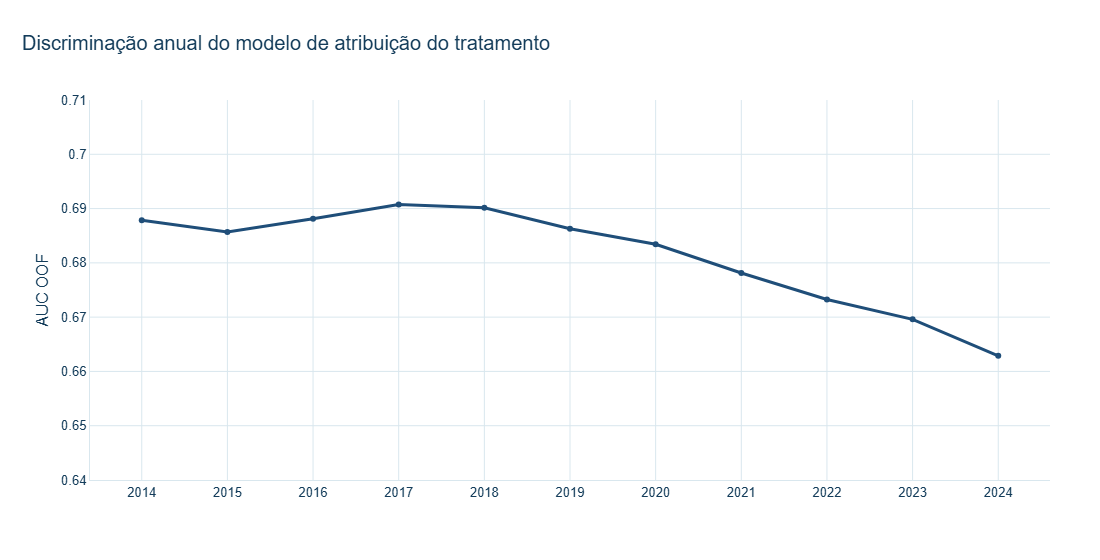

In [10]:
propensity = tabelas['propensity_anual'].sort_values('ano').set_index('ano')
display(propensity[['n', 'auc_oof', 'propensity_min', 'propensity_max',
                    't0_p05', 't0_p50', 't0_p95', 't1_p05', 't1_p50', 't1_p95']])

fig = go.Figure()
fig.add_scatter(x=propensity.index, y=propensity.auc_oof, mode='lines+markers',
                name='AUC OOF', line=dict(color='#1F4E79', width=3))
fig.update_yaxes(title='AUC OOF', range=[0.64, 0.71])
mostrar(fig, 'Discriminação anual do modelo de atribuição do tratamento', 'auc')

A AUC fica entre 0,663 e 0,691 e cai gradualmente desde o pico de 2017. A tendência indica que as covariáveis congeladas discriminam menos T nos anos recentes; isso não é métrica de outcome, não mede qualidade de uplift e não prova melhor identificação causal.

## 11. Overlap e suporte comum

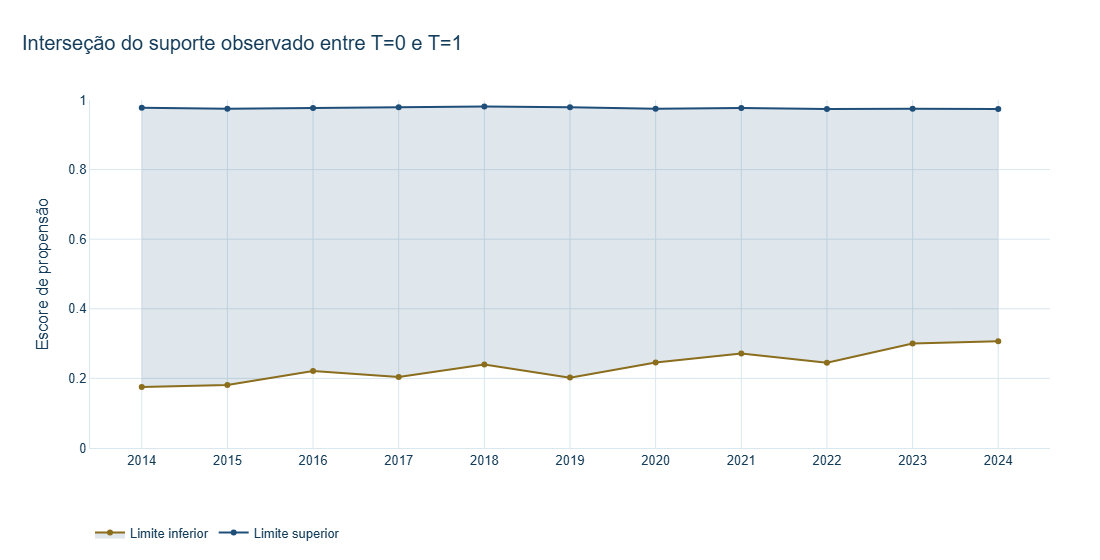

,suporte_comum_inferior,suporte_comum_superior
ano,,
2014,0.175582,0.977818
2015,0.181117,0.975101
2016,0.221001,0.977132
2017,0.204347,0.979448
2018,0.240198,0.981027
2019,0.202244,0.979239
2020,0.245821,0.975041
2021,0.271226,0.976798
2022,0.244770,0.974186


In [11]:
fig = go.Figure()
fig.add_scatter(x=propensity.index, y=propensity.suporte_comum_superior,
                mode='lines+markers', name='Limite superior', line=dict(color='#1F4E79'))
fig.add_scatter(x=propensity.index, y=propensity.suporte_comum_inferior,
                mode='lines+markers', name='Limite inferior', fill='tonexty',
                fillcolor='rgba(31,78,121,0.14)', line=dict(color='#8A6D1D'))
fig.update_yaxes(title='Escore de propensão', range=[0, 1])
mostrar(fig, 'Interseção do suporte observado entre T=0 e T=1', 'suporte_comum')
display(propensity[['suporte_comum_inferior', 'suporte_comum_superior']])

A interseção observada permanece ampla. O limite inferior sobe de 0,176 para 0,307, coerente com a maior prevalência de T=1; o limite superior fica entre 0,974 e 0,981. Suporte observado não demonstra intercambialidade nem garante suporte em toda combinação multidimensional de X.

## 12. Tamanho efetivo de amostra (ESS)

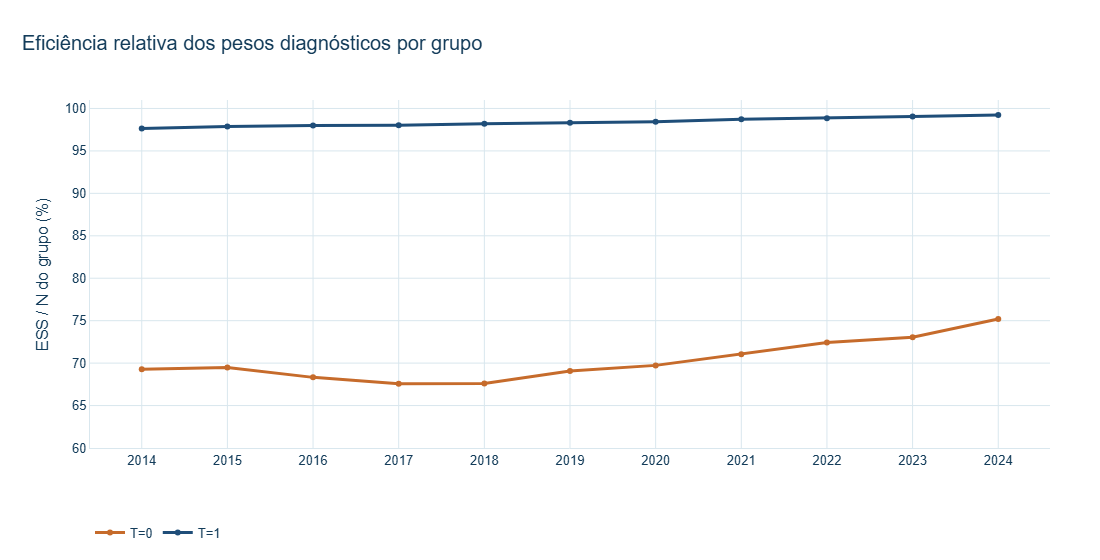

,n_t0,ess_t0,ess_t0_sobre_n,n_t1,ess_t1,ess_t1_sobre_n
ano,,,,,,
2014,577127,399886.955294,0.692892,2113992,2.064124e+06,0.976411
2015,565595,393057.329258,0.694945,2180251,2.133855e+06,0.978720
2016,518310,354116.862411,0.683214,2108284,2.065797e+06,0.979848
2017,511767,345829.164355,0.675755,2183909,2.140963e+06,0.980335
2018,499451,337670.823377,0.676084,2235022,2.194516e+06,0.981877
2019,465593,321627.414979,0.690791,2179790,2.143298e+06,0.983259
2020,444287,309819.462091,0.697341,2091024,2.058256e+06,0.984329
2021,399172,283571.236384,0.710399,2082095,2.055902e+06,0.987420
2022,379207,274647.285111,0.724267,2018419,1.995332e+06,0.988562


In [12]:
fig = go.Figure()
fig.add_scatter(x=propensity.index, y=100 * propensity.ess_t0_sobre_n,
                mode='lines+markers', name='T=0', line=dict(color='#C66B2B', width=3))
fig.add_scatter(x=propensity.index, y=100 * propensity.ess_t1_sobre_n,
                mode='lines+markers', name='T=1', line=dict(color='#1F4E79', width=3))
fig.update_yaxes(title='ESS / N do grupo (%)', range=[60, 101])
mostrar(fig, 'Eficiência relativa dos pesos diagnósticos por grupo', 'ess')
display(propensity[['n_t0', 'ess_t0', 'ess_t0_sobre_n', 'n_t1', 'ess_t1', 'ess_t1_sobre_n']])

O ESS relativo do controle melhora de 69,3% em 2014 para 75,2% em 2024; no tratado, cresce de 97,6% para 99,2%. O ESS absoluto do controle cai porque o próprio grupo encolhe, mas permanece acima de 232 mil em 2024. Não há sinal de colapso de ESS nesta rodada.

## 13. Frações fora de suporte diagnóstico

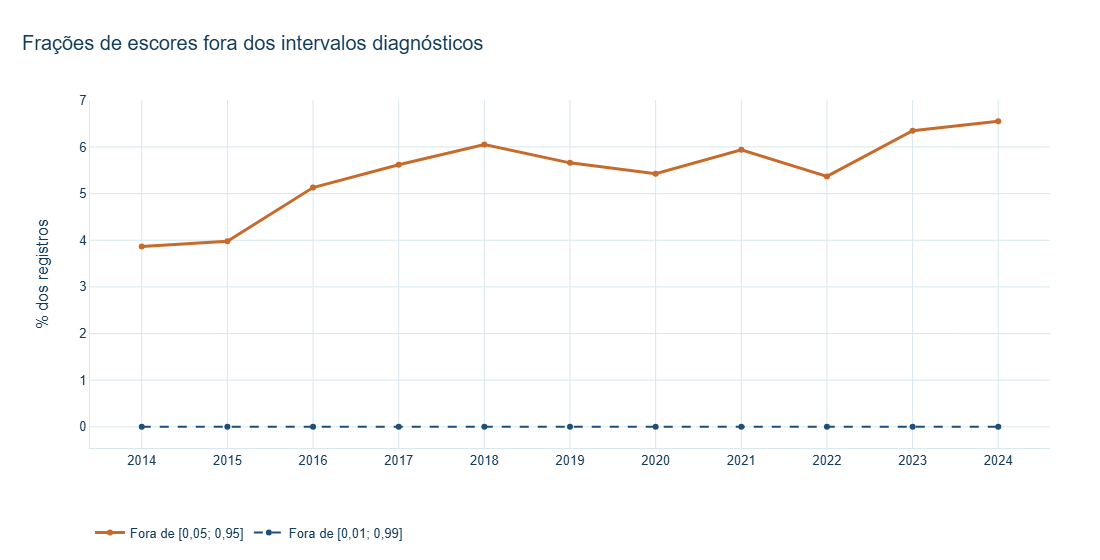

,fora_001_099_n,fora_001_099_fracao,fora_005_095_n,fora_005_095_fracao,fora_005_095_t0_n,fora_005_095_t1_n
ano,,,,,,
2014,0,0,103980,0.038638,4320,99660
2015,0,0,109265,0.039793,4799,104466
2016,0,0,134758,0.051305,5546,129212
2017,0,0,151448,0.056182,6424,145024
2018,0,0,165540,0.060538,7012,158528
2019,0,0,149709,0.056593,6446,143263
2020,0,0,137606,0.054276,6130,131476
2021,0,0,147349,0.059385,6438,140911
2022,0,0,128722,0.053687,5895,122827


In [13]:
fig = go.Figure()
fig.add_scatter(x=propensity.index, y=100 * propensity.fora_005_095_fracao,
                mode='lines+markers', name='Fora de [0,05; 0,95]',
                line=dict(color='#C66B2B', width=3))
fig.add_scatter(x=propensity.index, y=100 * propensity.fora_001_099_fracao,
                mode='lines+markers', name='Fora de [0,01; 0,99]',
                line=dict(color='#1F4E79', dash='dash'))
fig.update_yaxes(title='% dos registros')
mostrar(fig, 'Frações de escores fora dos intervalos diagnósticos', 'fracoes_fora')
display(propensity[['fora_001_099_n', 'fora_001_099_fracao',
                    'fora_005_095_n', 'fora_005_095_fracao',
                    'fora_005_095_t0_n', 'fora_005_095_t1_n']])

Nenhum registro fica fora de ([0,01;0,99]). Fora de ([0,05;0,95]), a fração oscila entre 3,86% e 6,55%, sem tendência monotônica. Cerca de 95,4%–95,9% desses registros pertencem a T=1, refletindo principalmente a cauda de alta propensão. Esses limites continuam diagnósticos e não definem trimming automático.

## 14. Perfis problemáticos e concentração das caudas

In [14]:
perfis = tabelas['perfis_fora_suporte']
top_perfis = (perfis[perfis.faixa.eq('fora_005_095')]
              .sort_values(['ano', 'n'], ascending=[True, False])
              .groupby('ano', as_index=False).head(5))
display(top_perfis[['ano', 'perfil', 'categoria', 'n', 'n_t0', 'n_t1',
                    'proporcao_no_perfil']])

ranking = (perfis[perfis.faixa.eq('fora_005_095')]
           .groupby(['perfil', 'categoria'], as_index=False).n.sum()
           .sort_values('n', ascending=False).head(12))
display(ranking)

,ano,perfil,categoria,n,n_t0,n_t1,proporcao_no_perfil
66,2014,ESCOLARIDADE_MAE,5,103331,4271,99060,0.299082
68,2014,RACA_COR_MAE,1,92928,3666,89262,0.093821
73,2014,PARIDADE_CAT,0,81858,3366,78492,0.072900
62,2014,FAIXA_IDADE_MAE,30-39,73504,2879,70625,0.092836
53,2014,UF_RESIDENCIA,35,45264,1818,43446,0.077999
103,2015,ESCOLARIDADE_MAE,5,108577,4744,103833,0.289027
104,2015,RACA_COR_MAE,1,96469,3979,92490,0.096655
109,2015,PARIDADE_CAT,0,86427,3756,82671,0.076063
99,2015,FAIXA_IDADE_MAE,30-39,77590,3212,74378,0.093508
90,2015,UF_RESIDENCIA,35,46896,2001,44895,0.079767


,perfil,categoria,n
3,ESCOLARIDADE_MAE,5,1495418
12,RACA_COR_MAE,1,1252651
10,PARIDADE_CAT,0,1103906
6,FAIXA_IDADE_MAE,30-39,1053536
36,UF_RESIDENCIA,35,621584
11,PARIDADE_CAT,1,423736
5,FAIXA_IDADE_MAE,20-29,330010
33,UF_RESIDENCIA,31,233582
15,RACA_COR_MAE,4,231891
37,UF_RESIDENCIA,41,182197


A cauda ([0,05;0,95]) concentra-se repetidamente em escolaridade nível 5, raça/cor nível 1 e paridade 0; em alguns anos, idade 30–39 também se destaca. Essas são contagens agregadas e sobrepostas entre dimensões — não devem ser somadas como pessoas distintas. Nenhum registro individual é versionado.

## 15. Comparação da janela principal 2014–2024

In [15]:
comparacao = tabelas['comparacao_janelas']
principal = comparacao[comparacao.janela.eq('principal')].sort_values('ano')
display(principal[['ano', 'auc_oof', 'pior_abs_smd', 'pior_abs_smd_temporal',
                   'fora_005_095_fracao', 'ess_t0_sobre_n', 'ess_t1_sobre_n',
                   'proporcao_t1', 'perfis_celula_pequena',
                   'perfis_tratamento_extremo']])

,ano,auc_oof,pior_abs_smd,pior_abs_smd_temporal,fora_005_095_fracao,ess_t0_sobre_n,ess_t1_sobre_n,proporcao_t1,perfis_celula_pequena,perfis_tratamento_extremo
0,2014,0.687864,0.441289,0.297774,0.038638,0.692892,0.976411,0.785544,1,0
1,2015,0.685684,0.436424,0.282677,0.039793,0.694945,0.978720,0.794018,1,0
2,2016,0.688118,0.434835,0.255416,0.051305,0.683214,0.979848,0.802668,1,0
3,2017,0.690765,0.439616,0.207089,0.056182,0.675755,0.980335,0.810153,1,0
4,2018,0.690134,0.441538,0.173409,0.060538,0.676084,0.981877,0.817350,1,0
5,2019,0.686274,0.428768,0.148066,0.056593,0.690791,0.983259,0.823998,1,0
6,2020,0.683425,0.415059,0.124845,0.054276,0.697341,0.984329,0.824760,1,0
7,2021,0.678126,0.388937,0.112270,0.059385,0.710399,0.987420,0.839126,1,0
8,2022,0.673258,0.384107,0.077517,0.053687,0.724267,0.988562,0.841841,1,0
9,2023,0.669593,0.384630,0.037938,0.063496,0.730608,0.990477,0.852251,1,0


Na janela principal, os anos iniciais são mais distantes de 2024 em composição, mas não exibem piora extrema de positividade, ESS ou suporte. O desequilíbrio bruto é elevado em toda a série; o AUC e o SMD bruto diminuem nos anos recentes. Assim, 2014–2017 não são descartados por preferência, mas a mudança de composição exige interpretação explícita.

## 16. Sensibilidade 2018–2024 (obrigatória)

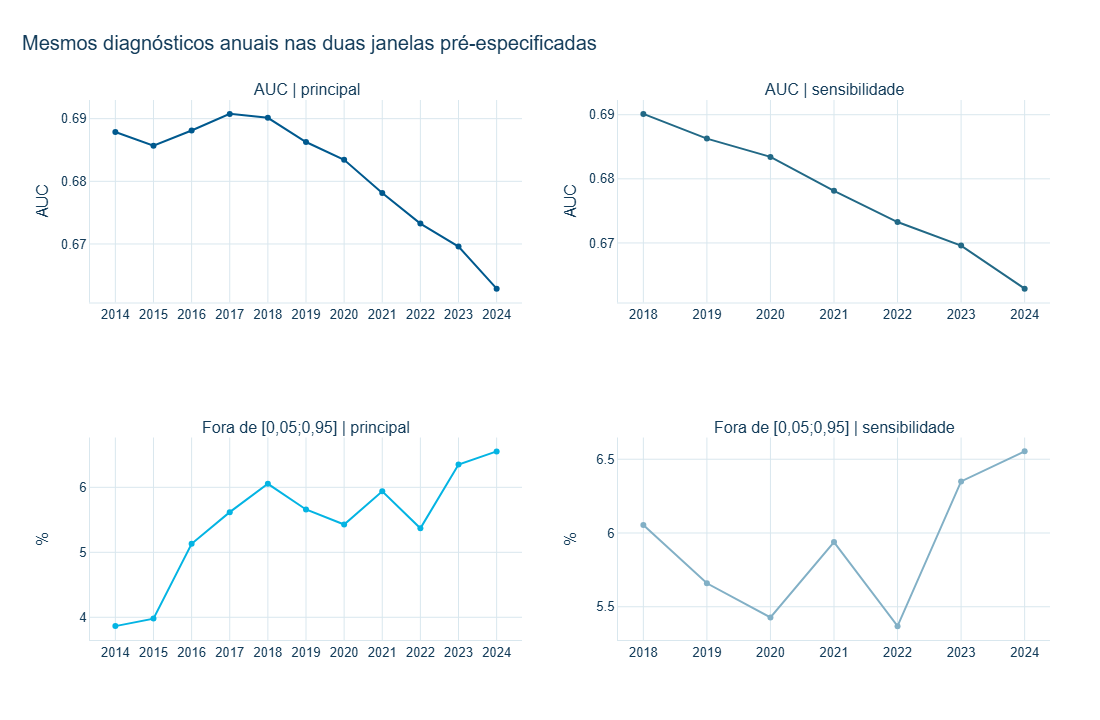

,ano,auc_oof,pior_abs_smd,pior_abs_smd_temporal,fora_005_095_fracao,ess_t0_sobre_n,ess_t1_sobre_n
11,2018,0.690134,0.441538,0.173409,0.060538,0.676084,0.981877
12,2019,0.686274,0.428768,0.148066,0.056593,0.690791,0.983259
13,2020,0.683425,0.415059,0.124845,0.054276,0.697341,0.984329
14,2021,0.678126,0.388937,0.112270,0.059385,0.710399,0.987420
15,2022,0.673258,0.384107,0.077517,0.053687,0.724267,0.988562
16,2023,0.669593,0.384630,0.037938,0.063496,0.730608,0.990477
17,2024,0.662873,0.375217,0.000000,0.065532,0.752054,0.992326


In [16]:
sensibilidade = comparacao[comparacao.janela.eq('sensibilidade')].sort_values('ano')
fig = make_subplots(rows=2, cols=2,
                    subplot_titles=['AUC | principal', 'AUC | sensibilidade',
                                    'Fora de [0,05;0,95] | principal',
                                    'Fora de [0,05;0,95] | sensibilidade'])
for coluna, dados_janela in enumerate([principal, sensibilidade], 1):
    fig.add_scatter(x=dados_janela.ano, y=dados_janela.auc_oof,
                    mode='lines+markers', showlegend=False, row=1, col=coluna)
    fig.add_scatter(x=dados_janela.ano, y=100 * dados_janela.fora_005_095_fracao,
                    mode='lines+markers', showlegend=False, row=2, col=coluna)
fig.update_yaxes(title='AUC', row=1)
fig.update_yaxes(title='%', row=2)
mostrar(fig, 'Mesmos diagnósticos anuais nas duas janelas pré-especificadas', 'janelas', altura=720)
display(sensibilidade[['ano', 'auc_oof', 'pior_abs_smd', 'pior_abs_smd_temporal',
                       'fora_005_095_fracao', 'ess_t0_sobre_n', 'ess_t1_sobre_n']])

A sensibilidade 2018–2024 preserva a leitura central: AUC e desequilíbrio bruto caem; o ESS relativo melhora; não surgem perfis marginais extremos; e a fração fora de ([0,05;0,95]) oscila sem deterioração monotônica. O recorte recente reduz, como esperado, a diferença de composição versus 2024.

## 17. Hipótese temporal 2021–2022 — análise descritiva

,periodo,auc_oof,pior_abs_smd,pior_abs_smd_temporal,fora_005_095_fracao,ess_t0_sobre_n,ess_t1_sobre_n,proporcao_t1,perfis_celula_pequena,perfis_tratamento_extremo
0,2014-2020,0.687466,0.433933,0.212754,0.051046,0.687289,0.980683,0.808356,1,0
1,2021,0.678126,0.388937,0.112270,0.059385,0.710399,0.987420,0.839126,1,0
2,2022,0.673258,0.384107,0.077517,0.053687,0.724267,0.988562,0.841841,1,0
3,2023-2024,0.666233,0.379924,0.018969,0.064514,0.741331,0.991401,0.857390,1,0


,ano,auc_oof_variacao_ano,pior_abs_smd_variacao_ano,pior_abs_smd_temporal_variacao_ano,fora_005_095_fracao_variacao_ano,ess_t0_sobre_n_variacao_ano,ess_t1_sobre_n_variacao_ano,proporcao_t1_variacao_ano
6,2020,-0.002849,-0.013709,-0.023222,-0.002317,0.006550,0.001070,0.000762
7,2021,-0.005299,-0.026122,-0.012575,0.005109,0.013058,0.003091,0.014365
8,2022,-0.004868,-0.004830,-0.034753,-0.005697,0.013869,0.001142,0.002715
9,2023,-0.003665,0.000523,-0.039580,0.009809,0.006340,0.001915,0.010411


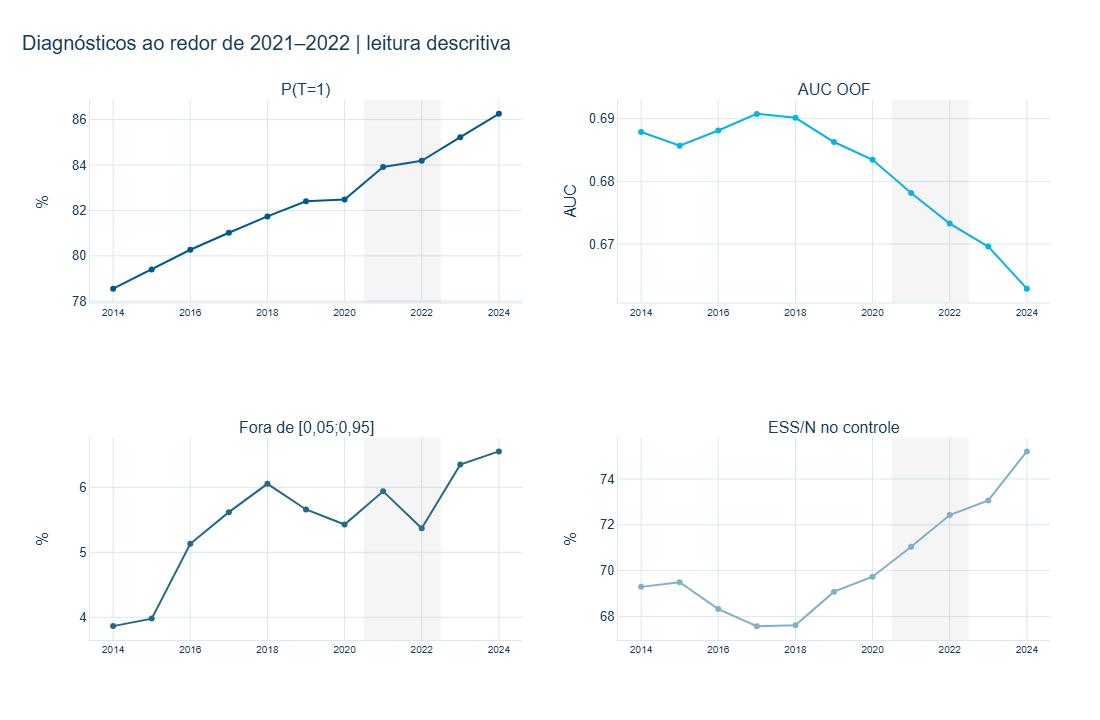

In [17]:
transicao = tabelas['transicao_2021_2022_anual'].sort_values('ano')
periodos = tabelas['transicao_2021_2022_periodos']
display(periodos)
display(transicao.loc[transicao.ano.between(2020, 2023),
    ['ano', 'auc_oof_variacao_ano', 'pior_abs_smd_variacao_ano',
     'pior_abs_smd_temporal_variacao_ano', 'fora_005_095_fracao_variacao_ano',
     'ess_t0_sobre_n_variacao_ano', 'ess_t1_sobre_n_variacao_ano',
     'proporcao_t1_variacao_ano']])

fig = make_subplots(rows=2, cols=2,
                    subplot_titles=['P(T=1)', 'AUC OOF',
                                    'Fora de [0,05;0,95]', 'ESS/N no controle'])
fig.add_scatter(x=transicao.ano, y=100 * transicao.proporcao_t1,
                mode='lines+markers', showlegend=False, row=1, col=1)
fig.add_scatter(x=transicao.ano, y=transicao.auc_oof,
                mode='lines+markers', showlegend=False, row=1, col=2)
fig.add_scatter(x=transicao.ano, y=100 * transicao.fora_005_095_fracao,
                mode='lines+markers', showlegend=False, row=2, col=1)
fig.add_scatter(x=transicao.ano, y=100 * transicao.ess_t0_sobre_n,
                mode='lines+markers', showlegend=False, row=2, col=2)
for linha in (1, 2):
    for coluna in (1, 2):
        fig.add_vrect(x0=2020.5, x1=2022.5, fillcolor='#999999', opacity=.10,
                      line_width=0, row=linha, col=coluna)
fig.update_yaxes(title='%', row=1, col=1)
fig.update_yaxes(title='AUC', row=1, col=2)
fig.update_yaxes(title='%', row=2, col=1)
fig.update_yaxes(title='%', row=2, col=2)
fig.update_xaxes(tickmode='array', tickvals=list(range(2014, 2025, 2)),
                 range=[2013.4, 2024.6], tickfont=dict(size=10))
mostrar(fig, 'Diagnósticos ao redor de 2021–2022 | leitura descritiva', 'transicao', altura=720)

Não aparece deterioração coincidente e generalizada em 2021–2022. Em 2021, T cresce 1,44 p.p., a fração fora de ([0,05;0,95]) sobe 0,51 p.p., mas o SMD bruto cai 0,026 e ESS/N melhora. Em 2022, composição converge mais para 2024, a fração fora cai 0,57 p.p. e ESS/N volta a melhorar. Logo, os diagnósticos de suporte não oferecem uma explicação única para a mudança descritiva de baixo peso vista no notebook 07.

Se uma rodada posterior exigir teste formal, uma especificação defensável seria regressão segmentada das métricas diagnósticas anuais, com pontos de quebra 2021 e 2022 fixados previamente, tendência basal e erros robustos; com apenas 11 pontos anuais, o poder e a interpretação seriam limitados. Nenhum teste de quebra é executado aqui.

## 18. Síntese

- **Balanço bruto:** materialmente diferente entre T=1 e T=0 em todos os anos.
- **Composição temporal:** diferenças maiores em 2014–2021, convergindo de forma gradual para 2024.
- **Tratamento:** crescimento persistente e redução absoluta do controle.
- **Positividade marginal:** nenhum perfil quase determinístico; uma célula pequena restrita a idade ignorada.
- **Propensity/overlap:** discriminação moderada e decrescente; suporte comum amplo; cauda acima de 0,95 presente, mas sem registros fora de ([0,01;0,99]).
- **ESS:** sem colapso; eficiência relativa melhora nos dois grupos.
- **2021–2022:** não há ruptura coerente em todos os diagnósticos de suporte.

Esses fatos são diagnósticos de viabilidade e comparabilidade; não são efeitos de tratamento.

## 19. Critérios para o notebook 09

**PRONTO_PARA_PLANEJAR_NOTEBOOK_09**, condicionado a:

1. manter ajustes separados por ano, sem compartilhar coeficientes;
2. preservar a janela principal 2014–2024 e reportar obrigatoriamente 2018–2024;
3. manter as sete covariáveis e o desenho temporal congelados;
4. reportar por ano SMD, suporte, caudas, ESS e N por grupo ao lado das futuras estimativas;
5. tratar a cauda de alta propensão e o encolhimento de T=0 como riscos de precisão/robustez;
6. não interpretar ajuste por observáveis como prova de ausência de confundimento;
7. pré-especificar antes dos resultados qualquer regra de trimming ou decisão de não estimar um ano.

Este é um protocolo descritivo; não foi criado gate binário pós-resultado.

## 20. Limitações

- Positividade é diagnosticada nas covariáveis observadas e em perfis marginais; combinações raras de alta dimensão podem continuar problemáticas.
- O propensity logístico depende da forma funcional e não valida identificação causal.
- SMD bruto não mede balanço após ponderação nesta fase.
- ESS é diagnóstico dos pesos derivados do propensity e não substitui incerteza completa.
- A composição muda e o preenchimento melhora ao longo do período, sobretudo nos anos iniciais.
- Não há identificador longitudinal da mãe; dependência familiar não é mensurável.
- Não foram executados testes formais de quebra estrutural.
- Nenhum efeito causal, heterogeneidade ou política de decisão foi estimado neste notebook.